In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm, chi2

import os
import warnings

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
print("Current working directory:")
print(os.getcwd())

print("\nAvailable CSV and Excel files:")

files = [
    f for f in os.listdir()
    if f.lower().endswith((".csv", ".xlsx", ".xls"))
]

for i, f in enumerate(files):
    print(i, ":", f)

print("\nEnter the numbers corresponding to your datasets.")

nifty_file = files[int(input("NIFTY 50 file number: "))]
india_vix_file = files[int(input("India VIX file number: "))]
usa_vix_file = files[int(input("US VIX file number: "))]

print("\nSelected files:")
print("NIFTY:", nifty_file)
print("India VIX:", india_vix_file)
print("US VIX:", usa_vix_file)

Current working directory:
C:\Users\valat

Available CSV and Excel files:
0 : Baseline_vs_Genuine_TVTP.csv
1 : Common_Dates_NIFTY_IndiaVIX_USAVIX.csv
2 : Complete_Model_Comparison.csv
3 : Corrected_TVTP_KAN_Test_Results.csv
4 : credit_risk_final_predictions.csv
5 : credit_risk_model_comparison.csv
6 : default of credit card clients.csv
7 : Diebold_Mariano_Test.csv
8 : Final_Model_Comparison.csv
9 : final_model_metrics.csv
10 : Final_Three_Model_Comparison.csv
11 : Final_TVTP_Forecasts.csv
12 : FINAL_TVTP_SVAR_KAN_METRICS.csv
13 : FINAL_TVTP_SVAR_KAN_TEST_RESULTS.csv
14 : FULL_COMMON_DATA_NIFTY_INDIA_VIX_USA_VIX.csv
15 : Genuine_TVTP_SVAR_KAN_Metrics.csv
16 : Genuine_TVTP_SVAR_KAN_Test_Results.csv
17 : INDIA_VIX.csv
18 : MAE_Model_Comparison.csv
19 : Multivariate_HMM_Durations.csv
20 : Multivariate_HMM_SVAR_NIFTY_FEVD.csv
21 : Multivariate_HMM_Test_Probabilities.csv
22 : Multivariate_HMM_Test_Regimes.csv
23 : Multivariate_HMM_Train_Regimes.csv
24 : Multivariate_HMM_Transition_Matrix.csv

NIFTY 50 file number:  25
India VIX file number:  17
US VIX file number:  40



Selected files:
NIFTY: Nifty 50 Historical Data (2).csv
India VIX: INDIA_VIX.csv
US VIX: USA_VIX.csv


In [3]:
def load_data(filename):
    if filename.lower().endswith(".csv"):
        return pd.read_csv(filename)
    return pd.read_excel(filename)

nifty_raw = load_data(nifty_file)
india_vix_raw = load_data(india_vix_file)
usa_vix_raw = load_data(usa_vix_file)

for name, df in [
    ("NIFTY", nifty_raw),
    ("India VIX", india_vix_raw),
    ("US VIX", usa_vix_raw)
]:
    print("\n", "=" * 50)
    print(name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


NIFTY
Shape: (4620, 7)
Columns: ['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']
      Date     Price      Open      High       Low    Vol. Change %
15-09-2026 23,118.60 23,576.15 23,588.30 23,118.60 338.84M   -1.19%
11-09-2026 23,398.10 23,270.30 23,448.10 23,231.40 293.03M   -0.34%
10-09-2026 23,477.80 23,446.60 23,494.95 23,380.10 253.25M    0.20%

India VIX
Shape: (4547, 6)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Change %']
      Date  Open  High   Low  Close Change %
28-03-2008 46.15 46.15 28.43  33.07  -11.29%
31-03-2008 33.07 37.92 28.57  35.14    6.26%
01-04-2008 31.24 38.38 28.59  35.10   -0.11%

US VIX
Shape: (9272, 5)
Columns: ['DATE', 'OPEN', 'HIGH', 'LOW', 'CLOSE']
      DATE  OPEN  HIGH   LOW  CLOSE
01/02/1990 17.24 17.24 17.24  17.24
01/03/1990 18.19 18.19 18.19  18.19
01/04/1990 19.22 19.22 19.22  19.22


In [4]:
def choose_column(df, dataset_name, kind):
    columns = df.columns.tolist()

    if kind == "date":
        candidates = ["Date", "DATE", "date", "Trade Date", "Timestamp"]
    else:
        candidates = [
            "Price", "Close", "CLOSE", "close",
            "Closing Price", "Adj Close", "Last", "VALUE"
        ]

    matches = [c for c in candidates if c in columns]

    print(f"\n{dataset_name} — {kind} column")
    for i, col in enumerate(columns):
        print(i, ":", col)

    if len(matches) == 1:
        chosen = matches[0]
        print("Automatically selected:", chosen)
        return chosen

    idx = int(input(f"Enter column number for {dataset_name} {kind}: "))
    return columns[idx]


nifty_date_col = choose_column(nifty_raw, "NIFTY", "date")
nifty_price_col = choose_column(nifty_raw, "NIFTY", "price")

india_date_col = choose_column(india_vix_raw, "India VIX", "date")
india_price_col = choose_column(india_vix_raw, "India VIX", "price")

usa_date_col = choose_column(usa_vix_raw, "US VIX", "date")
usa_price_col = choose_column(usa_vix_raw, "US VIX", "price")


NIFTY — date column
0 : Date
1 : Price
2 : Open
3 : High
4 : Low
5 : Vol.
6 : Change %
Automatically selected: Date

NIFTY — price column
0 : Date
1 : Price
2 : Open
3 : High
4 : Low
5 : Vol.
6 : Change %
Automatically selected: Price

India VIX — date column
0 : Date
1 : Open
2 : High
3 : Low
4 : Close
5 : Change %
Automatically selected: Date

India VIX — price column
0 : Date
1 : Open
2 : High
3 : Low
4 : Close
5 : Change %
Automatically selected: Close

US VIX — date column
0 : DATE
1 : OPEN
2 : HIGH
3 : LOW
4 : CLOSE
Automatically selected: DATE

US VIX — price column
0 : DATE
1 : OPEN
2 : HIGH
3 : LOW
4 : CLOSE
Automatically selected: CLOSE


In [5]:
def clean_market_data(df, date_col, price_col, new_name):

    temp = df[[date_col, price_col]].copy()
    temp.columns = ["Date", new_name]

    temp["Date"] = pd.to_datetime(
        temp["Date"],
        errors="coerce",
        dayfirst=False
    )

    temp[new_name] = (
        temp[new_name]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    temp[new_name] = pd.to_numeric(
        temp[new_name],
        errors="coerce"
    )

    temp = temp.dropna(subset=["Date", new_name])

    temp = temp[temp[new_name] > 0]

    temp = temp.drop_duplicates(subset=["Date"], keep="last")

    temp = temp.sort_values("Date").reset_index(drop=True)

    return temp


nifty = clean_market_data(
    nifty_raw, nifty_date_col, nifty_price_col, "NIFTY"
)

india_vix = clean_market_data(
    india_vix_raw, india_date_col, india_price_col, "India_VIX"
)

usa_vix = clean_market_data(
    usa_vix_raw, usa_date_col, usa_price_col, "USA_VIX"
)

print("NIFTY:", nifty.shape)
print("India VIX:", india_vix.shape)
print("US VIX:", usa_vix.shape)

NIFTY: (4620, 2)
India VIX: (4547, 2)
US VIX: (9272, 2)


In [6]:
data = nifty.merge(
    india_vix,
    on="Date",
    how="inner"
)

data = data.merge(
    usa_vix,
    on="Date",
    how="inner"
)

data = data.sort_values("Date").reset_index(drop=True)

print("Combined dataset shape:", data.shape)

if data.empty:
    raise ValueError(
        "No common dates found. Check date parsing and dataset ranges."
    )

print("\nDate range:")
print(data["Date"].min(), "to", data["Date"].max())

print("\nMissing values:")
print(data.isnull().sum())

display(data.head())

Combined dataset shape: (4430, 4)

Date range:
2008-03-28 00:00:00 to 2026-08-14 00:00:00

Missing values:
Date         0
NIFTY        0
India_VIX    0
USA_VIX      0
dtype: int64


,Date,NIFTY,India_VIX,USA_VIX
0,2008-03-28,4942.00,33.07,25.71
1,2008-03-31,4734.50,35.14,25.61
2,2008-04-01,4739.55,35.10,22.68
3,2008-04-02,4754.20,33.62,23.43
4,2008-04-03,4771.60,36.68,23.21


In [7]:
data.to_csv("market_risk_cleaned_data.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [8]:
data["NIFTY_Return"] = 100 * np.log(
    data["NIFTY"] / data["NIFTY"].shift(1)
)

data["India_VIX_Change"] = data["India_VIX"].pct_change() * 100

data["USA_VIX_Change"] = data["USA_VIX"].pct_change() * 100

data = data.dropna().reset_index(drop=True)

print("Final observations:", len(data))

display(data.head())

Final observations: 4429


,Date,NIFTY,India_VIX,USA_VIX,NIFTY_Return,India_VIX_Change,USA_VIX_Change
0,2008-03-31,4734.50,35.14,25.61,-4.289398,6.259450,-0.388954
1,2008-04-01,4739.55,35.10,22.68,0.106607,-0.113830,-11.440843
2,2008-04-02,4754.20,33.62,23.43,0.308624,-4.216524,3.306878
3,2008-04-03,4771.60,36.68,23.21,0.365324,9.101725,-0.938967
4,2008-04-04,4647.00,36.93,22.45,-2.645983,0.681570,-3.274451


In [9]:
columns = [
    "NIFTY_Return",
    "India_VIX",
    "USA_VIX",
    "India_VIX_Change",
    "USA_VIX_Change"
]

summary = data[columns].describe()

display(summary)

summary.to_csv("descriptive_statistics.csv")

,NIFTY_Return,India_VIX,USA_VIX,India_VIX_Change,USA_VIX_Change
count,4429.000000,4429.000000,4429.000000,4429.000000,4429.000000
mean,0.036022,19.688282,19.763509,0.152803,0.307689
std,1.253797,9.019714,8.766382,6.080593,8.341012
min,-13.903754,9.150000,9.140000,-37.512558,-35.753870
25%,-0.518796,14.045000,14.120000,-2.869492,-4.247955
50%,0.057947,17.010000,17.400000,-0.273598,-0.650289
75%,0.647176,21.877500,22.480000,2.573073,3.647159
max,16.334315,85.130000,82.690000,65.703381,115.597920


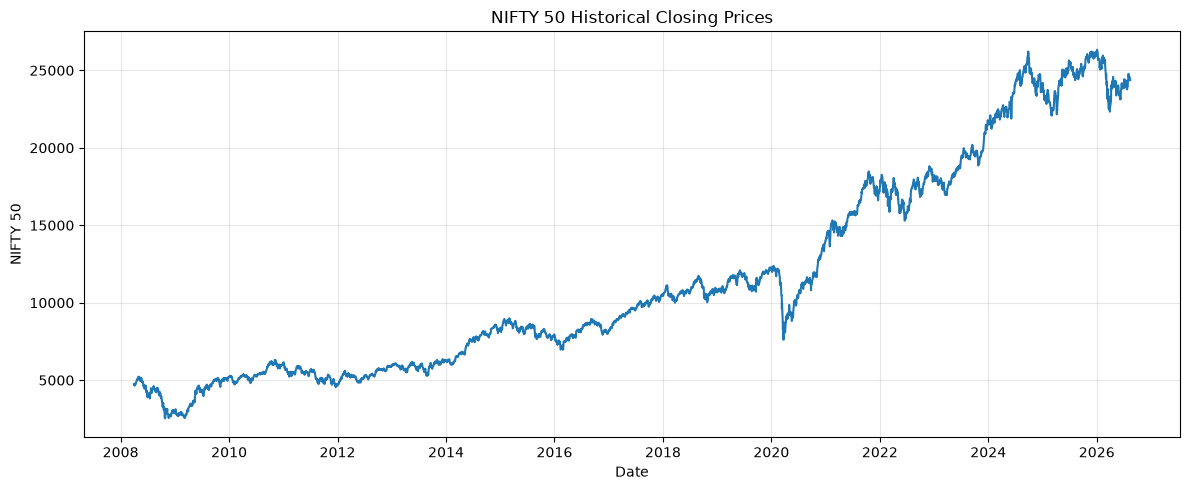

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(data["Date"], data["NIFTY"])

plt.title("NIFTY 50 Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("NIFTY 50")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

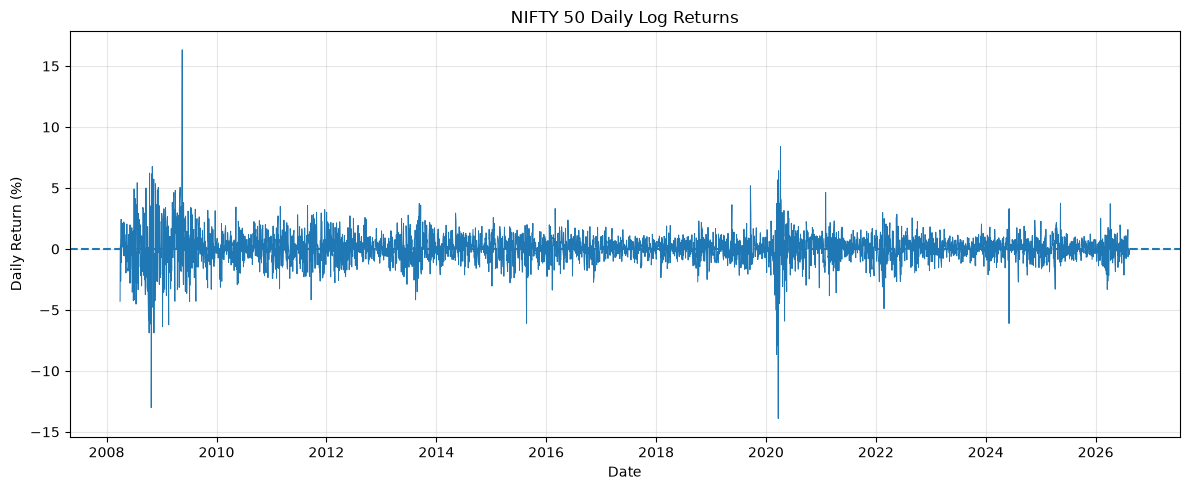

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    data["Date"],
    data["NIFTY_Return"],
    linewidth=0.7
)

plt.axhline(0, linestyle="--")

plt.title("NIFTY 50 Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

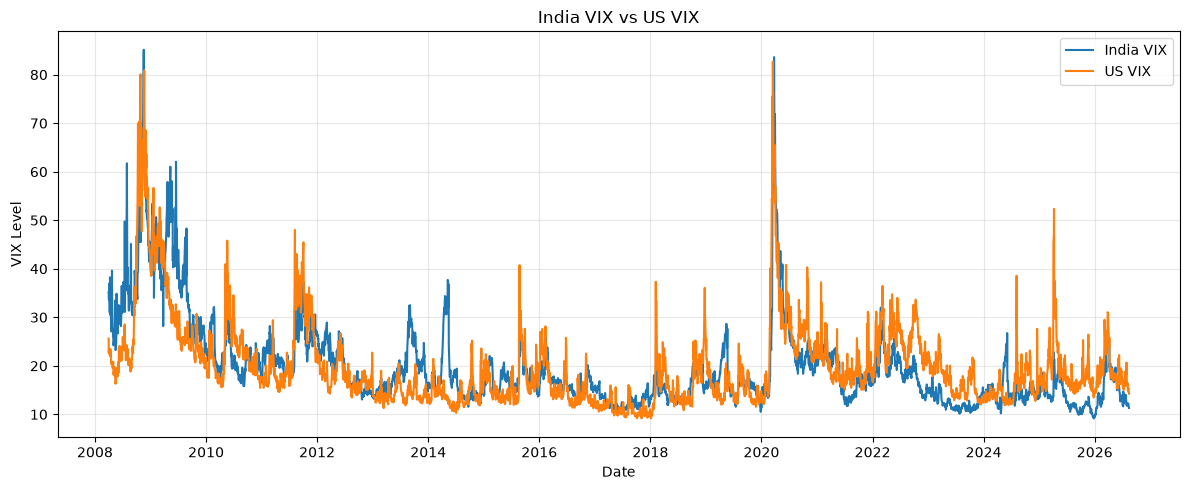

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    data["Date"],
    data["India_VIX"],
    label="India VIX"
)

plt.plot(
    data["Date"],
    data["USA_VIX"],
    label="US VIX"
)

plt.title("India VIX vs US VIX")
plt.xlabel("Date")
plt.ylabel("VIX Level")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

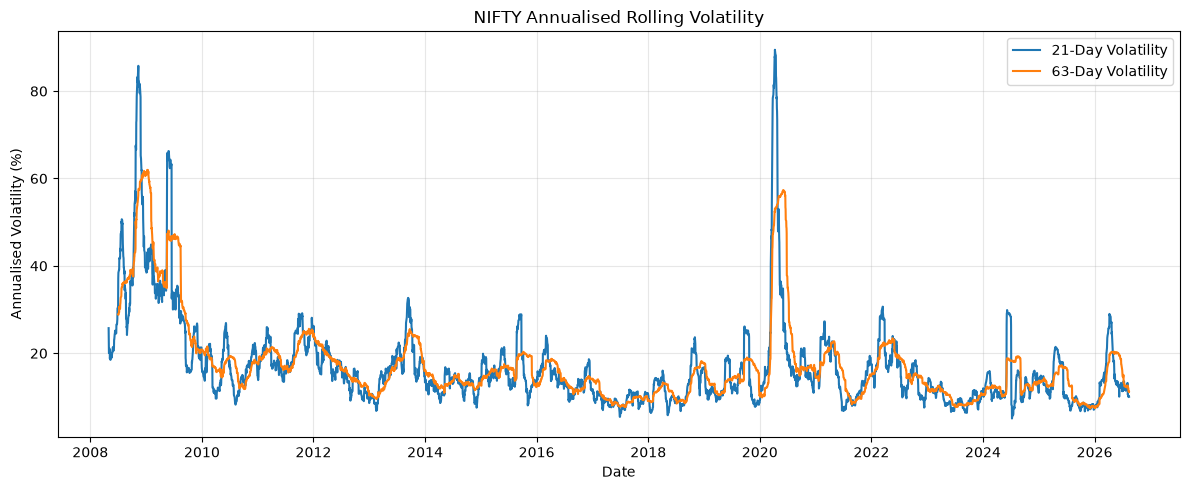

In [13]:
data["Volatility_21D"] = (
    data["NIFTY_Return"].rolling(21).std() * np.sqrt(252)
)

data["Volatility_63D"] = (
    data["NIFTY_Return"].rolling(63).std() * np.sqrt(252)
)

plt.figure(figsize=(12, 5))

plt.plot(
    data["Date"],
    data["Volatility_21D"],
    label="21-Day Volatility"
)

plt.plot(
    data["Date"],
    data["Volatility_63D"],
    label="63-Day Volatility"
)

plt.title("NIFTY Annualised Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Annualised Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Correlation Matrix


,NIFTY_Return,India_VIX,USA_VIX,India_VIX_Change,USA_VIX_Change
NIFTY_Return,1.000000,-0.053918,-0.111982,-0.427650,-0.217737
India_VIX,-0.053918,1.000000,0.771711,0.106662,-0.013071
USA_VIX,-0.111982,0.771711,1.000000,0.086307,0.123461
India_VIX_Change,-0.427650,0.106662,0.086307,1.000000,0.182302
USA_VIX_Change,-0.217737,-0.013071,0.123461,0.182302,1.000000


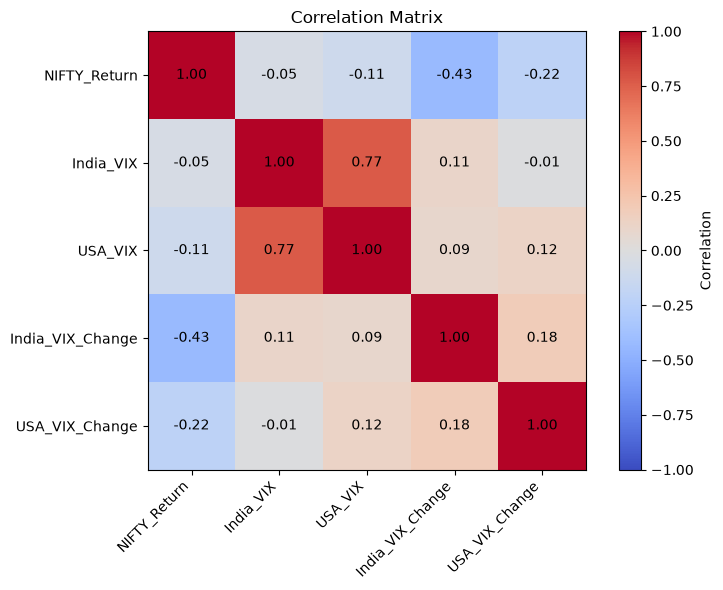

In [14]:
corr_columns = [
    "NIFTY_Return",
    "India_VIX",
    "USA_VIX",
    "India_VIX_Change",
    "USA_VIX_Change"
]

correlation = data[corr_columns].corr()

print("Correlation Matrix")
display(correlation)

plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_columns)),
    corr_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr_columns)),
    corr_columns
)

for i in range(len(corr_columns)):
    for j in range(len(corr_columns)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [15]:
returns = data["NIFTY_Return"].dropna()

def historical_risk(returns, confidence):

    alpha = 1 - confidence

    cutoff = np.quantile(returns, alpha)

    var = -cutoff

    es = -returns[returns <= cutoff].mean()

    return var, es


hist_var_95, hist_es_95 = historical_risk(returns, 0.95)
hist_var_99, hist_es_99 = historical_risk(returns, 0.99)

print("HISTORICAL RISK MEASURES")
print(f"95% VaR: {hist_var_95:.4f}%")
print(f"95% ES : {hist_es_95:.4f}%")
print(f"99% VaR: {hist_var_99:.4f}%")
print(f"99% ES : {hist_es_99:.4f}%")

HISTORICAL RISK MEASURES
95% VaR: 1.8119%
95% ES : 2.9482%
99% VaR: 3.4807%
99% ES : 5.1897%


In [16]:
mu = returns.mean()
sigma = returns.std(ddof=1)

def parametric_risk(mu, sigma, confidence):

    alpha = 1 - confidence

    z = norm.ppf(alpha)

    var = -(mu + sigma * z)

    es = -mu + sigma * norm.pdf(z) / alpha

    return var, es


param_var_95, param_es_95 = parametric_risk(
    mu, sigma, 0.95
)

param_var_99, param_es_99 = parametric_risk(
    mu, sigma, 0.99
)

print("PARAMETRIC RISK MEASURES")
print(f"95% VaR: {param_var_95:.4f}%")
print(f"95% ES : {param_es_95:.4f}%")
print(f"99% VaR: {param_var_99:.4f}%")
print(f"99% ES : {param_es_99:.4f}%")

PARAMETRIC RISK MEASURES
95% VaR: 2.0263%
95% ES : 2.5502%
99% VaR: 2.8807%
99% ES : 3.3056%


In [17]:
risk_comparison = pd.DataFrame({
    "Method": [
        "Historical",
        "Historical",
        "Parametric Normal",
        "Parametric Normal"
    ],
    "Confidence": ["95%", "99%", "95%", "99%"],
    "VaR_Percent": [
        hist_var_95,
        hist_var_99,
        param_var_95,
        param_var_99
    ],
    "ES_Percent": [
        hist_es_95,
        hist_es_99,
        param_es_95,
        param_es_99
    ]
})

display(risk_comparison.round(4))

risk_comparison.to_csv(
    "var_es_comparison.csv",
    index=False
)

,Method,Confidence,VaR_Percent,ES_Percent
0,Historical,95%,1.8119,2.9482
1,Historical,99%,3.4807,5.1897
2,Parametric Normal,95%,2.0263,2.5502
3,Parametric Normal,99%,2.8807,3.3056


In [18]:
split = int(len(data) * 0.80)

train_data = data.iloc[:split].copy()
test_data = data.iloc[split:].copy()

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("Training period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("Testing period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training observations: 3543
Testing observations: 886
Training period:
2008-03-31 00:00:00 to 2023-01-03 00:00:00
Testing period:
2023-01-04 00:00:00 to 2026-08-14 00:00:00


In [19]:
stress_data = data.copy()

stress_data["Lagged_USA_VIX_Change"] = (
    stress_data["USA_VIX_Change"].shift(1)
)

stress_data = stress_data.dropna(
    subset=[
        "NIFTY_Return",
        "India_VIX_Change",
        "Lagged_USA_VIX_Change"
    ]
)

stress_train = stress_data[
    stress_data["Date"] <= train_data["Date"].max()
].copy()

X_stress = stress_train[
    ["India_VIX_Change", "Lagged_USA_VIX_Change"]
].to_numpy()

y_stress = stress_train["NIFTY_Return"].to_numpy()

X_stress = np.column_stack([
    np.ones(len(X_stress)),
    X_stress
])

coefficients = np.linalg.lstsq(
    X_stress,
    y_stress,
    rcond=None
)[0]

print("Regression coefficients:")
print("Intercept:", coefficients[0])
print("India VIX change:", coefficients[1])
print("Lagged US VIX change:", coefficients[2])

Regression coefficients:
Intercept: 0.05744434987155766
India VIX change: -0.0843689403928624
Lagged US VIX change: -0.019048713925673325


In [20]:
scenarios = pd.DataFrame({
    "Scenario": [
        "Baseline",
        "India VIX +25%",
        "US VIX +25%",
        "Both VIX +25%",
        "Both VIX +50%"
    ],
    "India_VIX_Shock": [0, 25, 0, 25, 50],
    "USA_VIX_Shock": [0, 0, 25, 25, 50]
})

scenarios["Estimated_NIFTY_Return"] = (
    coefficients[0]
    + coefficients[1] * scenarios["India_VIX_Shock"]
    + coefficients[2] * scenarios["USA_VIX_Shock"]
)

scenarios["Estimated_Loss_Percent"] = np.maximum(
    -scenarios["Estimated_NIFTY_Return"],
    0
)

display(scenarios.round(4))

,Scenario,India_VIX_Shock,USA_VIX_Shock,Estimated_NIFTY_Return,Estimated_Loss_Percent
0,Baseline,0,0,0.0574,0.0000
1,India VIX +25%,25,0,-2.0518,2.0518
2,US VIX +25%,0,25,-0.4188,0.4188
3,Both VIX +25%,25,25,-2.5280,2.5280
4,Both VIX +50%,50,50,-5.1134,5.1134


In [21]:
portfolio_value = 1000000

scenarios["Estimated_Loss_INR"] = (
    portfolio_value
    * scenarios["Estimated_Loss_Percent"]
    / 100
)

display(scenarios.round(2))

scenarios.to_csv(
    "stress_testing_results.csv",
    index=False
)

,Scenario,India_VIX_Shock,USA_VIX_Shock,Estimated_NIFTY_Return,Estimated_Loss_Percent,Estimated_Loss_INR
0,Baseline,0,0,0.06,0.00,0.00
1,India VIX +25%,25,0,-2.05,2.05,20517.79
2,US VIX +25%,0,25,-0.42,0.42,4187.73
3,Both VIX +25%,25,25,-2.53,2.53,25279.97
4,Both VIX +50%,50,50,-5.11,5.11,51134.38


In [22]:
window = 250

data["VaR_95_Rolling"] = (
    -data["NIFTY_Return"]
    .shift(1)
    .rolling(window)
    .quantile(0.05)
)

data["VaR_99_Rolling"] = (
    -data["NIFTY_Return"]
    .shift(1)
    .rolling(window)
    .quantile(0.01)
)

backtest = data.iloc[split:].copy()

backtest = backtest.dropna(
    subset=["VaR_95_Rolling", "VaR_99_Rolling"]
)

print("Backtesting observations:", len(backtest))

Backtesting observations: 886


In [23]:
backtest["Loss"] = -backtest["NIFTY_Return"]

backtest["Exception_95"] = (
    backtest["Loss"] > backtest["VaR_95_Rolling"]
).astype(int)

backtest["Exception_99"] = (
    backtest["Loss"] > backtest["VaR_99_Rolling"]
).astype(int)

n = len(backtest)

if n == 0:
    raise ValueError("Not enough observations for backtesting.")

exceptions_95 = backtest["Exception_95"].sum()
exceptions_99 = backtest["Exception_99"].sum()

print("95% VaR exceptions:", exceptions_95)
print("Expected approximately:", n * 0.05)

print("\n99% VaR exceptions:", exceptions_99)
print("Expected approximately:", n * 0.01)

95% VaR exceptions: 53
Expected approximately: 44.300000000000004

99% VaR exceptions: 15
Expected approximately: 8.86


In [24]:
def kupiec_test(exceptions, observations, alpha):

    x = exceptions
    n = observations

    p_hat = x / n

    def log_likelihood(p):
        if p == 0:
            return 0 if x == 0 else -np.inf
        if p == 1:
            return 0 if x == n else -np.inf

        return (
            x * np.log(p)
            + (n - x) * np.log(1 - p)
        )

    lr = -2 * (
        log_likelihood(alpha)
        - log_likelihood(p_hat)
    )

    p_value = chi2.sf(lr, df=1)

    return lr, p_value


lr95, p95 = kupiec_test(exceptions_95, n, 0.05)
lr99, p99 = kupiec_test(exceptions_99, n, 0.01)

print("KUPIEC BACKTEST")

print("\n95% VaR")
print("LR statistic:", round(lr95, 4))
print("P-value:", round(p95, 4))

print("\n99% VaR")
print("LR statistic:", round(lr99, 4))
print("P-value:", round(p99, 4))

KUPIEC BACKTEST

95% VaR
LR statistic: 1.6968
P-value: 0.1927

99% VaR
LR statistic: 3.5582
P-value: 0.0593


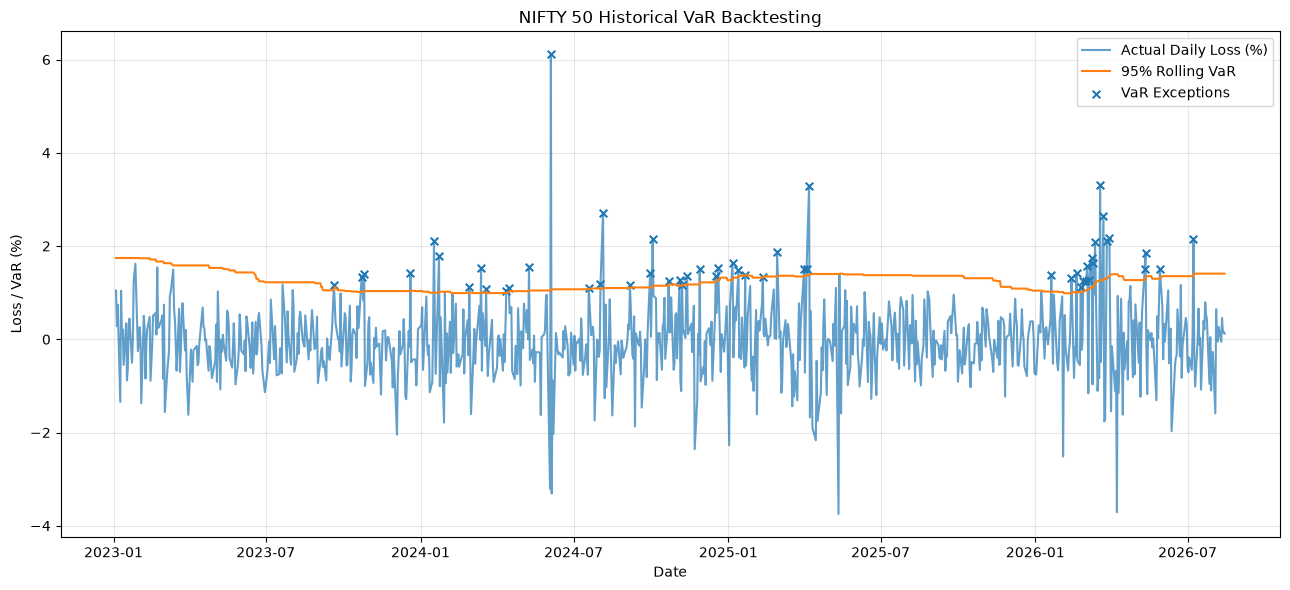

In [25]:
plt.figure(figsize=(13, 6))

plt.plot(
    backtest["Date"],
    backtest["Loss"],
    label="Actual Daily Loss (%)",
    alpha=0.7
)

plt.plot(
    backtest["Date"],
    backtest["VaR_95_Rolling"],
    label="95% Rolling VaR",
    linewidth=1.5
)

breaches = backtest[
    backtest["Exception_95"] == 1
]

plt.scatter(
    breaches["Date"],
    breaches["Loss"],
    label="VaR Exceptions",
    marker="x",
    s=30
)

plt.title("NIFTY 50 Historical VaR Backtesting")
plt.xlabel("Date")
plt.ylabel("Loss / VaR (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("var_backtesting.png", dpi=200)
plt.show()

In [26]:
data.to_csv(
    "market_risk_analysis.csv",
    index=False
)

backtest.to_csv(
    "var_backtesting_results.csv",
    index=False
)

backtesting_summary = pd.DataFrame({
    "Confidence": ["95%", "99%"],
    "Observations": [n, n],
    "Exceptions": [exceptions_95, exceptions_99],
    "Expected_Exceptions": [n * 0.05, n * 0.01],
    "Kupiec_LR": [lr95, lr99],
    "Kupiec_P_Value": [p95, p99]
})

backtesting_summary.to_csv(
    "backtesting_summary.csv",
    index=False
)

print("All project output files saved successfully.")

All project output files saved successfully.


In [27]:
print("NIFTY dates:")
print(nifty_raw["Date"].head())

print("\nIndia VIX dates:")
print(india_vix_raw["Date"].head())

print("\nUS VIX dates:")
print(usa_vix_raw["DATE"].head())

NIFTY dates:
0    15-09-2026
1    11-09-2026
2    10-09-2026
3    09-09-2026
4    08-09-2026
Name: Date, dtype: str

India VIX dates:
0    28-03-2008
1    31-03-2008
2    01-04-2008
3    02-04-2008
4    03-04-2008
Name: Date, dtype: str

US VIX dates:
0    01/02/1990
1    01/03/1990
2    01/04/1990
3    01/05/1990
4    01/08/1990
Name: DATE, dtype: str


In [28]:
def clean_market_data_fixed(df, date_col, price_col, new_name, date_format):
    temp = df[[date_col, price_col]].copy()
    temp.columns = ["Date", new_name]

    temp["Date"] = pd.to_datetime(
        temp["Date"].astype(str).str.strip(),
        format=date_format,
        errors="coerce"
    )

    temp[new_name] = pd.to_numeric(
        temp[new_name].astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

    temp = temp.dropna(subset=["Date", new_name])
    temp = temp[temp[new_name] > 0]
    temp = temp.drop_duplicates(subset=["Date"], keep="last")
    temp = temp.sort_values("Date").reset_index(drop=True)

    return temp


nifty = clean_market_data_fixed(
    nifty_raw, "Date", "Price", "NIFTY", "%d-%m-%Y"
)

india_vix = clean_market_data_fixed(
    india_vix_raw, "Date", "Close", "India_VIX", "%d-%m-%Y"
)

usa_vix = clean_market_data_fixed(
    usa_vix_raw, "DATE", "CLOSE", "USA_VIX", "%m/%d/%Y"
)

print("NIFTY:", nifty.shape)
print("India VIX:", india_vix.shape)
print("US VIX:", usa_vix.shape)

NIFTY: (4620, 2)
India VIX: (4547, 2)
US VIX: (9272, 2)


In [29]:
data = nifty.merge(
    india_vix,
    on="Date",
    how="inner",
    validate="one_to_one"
)

data = data.merge(
    usa_vix,
    on="Date",
    how="inner",
    validate="one_to_one"
)

data = data.sort_values("Date").reset_index(drop=True)

print("Combined shape:", data.shape)
print("Start date:", data["Date"].min())
print("End date:", data["Date"].max())

display(data.head())
display(data.tail())

assert data["Date"].is_monotonic_increasing
assert not data["Date"].duplicated().any()
assert data[["NIFTY", "India_VIX", "USA_VIX"]].notna().all().all()

Combined shape: (4430, 4)
Start date: 2008-03-28 00:00:00
End date: 2026-08-14 00:00:00


,Date,NIFTY,India_VIX,USA_VIX
0,2008-03-28,4942.00,33.07,25.71
1,2008-03-31,4734.50,35.14,25.61
2,2008-04-01,4739.55,35.10,22.68
3,2008-04-02,4754.20,33.62,23.43
4,2008-04-03,4771.60,36.68,23.21


,Date,NIFTY,India_VIX,USA_VIX
4425,2026-08-10,24583.80,12.2450,15.46
4426,2026-08-11,24471.70,11.8550,15.28
4427,2026-08-12,24435.95,11.6900,14.55
4428,2026-08-13,24395.85,11.4175,14.63
4429,2026-08-14,24366.00,11.3050,14.25


In [30]:
data["NIFTY_Return"] = (
    100 * np.log(data["NIFTY"] / data["NIFTY"].shift(1))
)

data["India_VIX_Change"] = data["India_VIX"].pct_change() * 100
data["USA_VIX_Change"] = data["USA_VIX"].pct_change() * 100

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna().reset_index(drop=True)

print("Observations after return calculation:", len(data))
print("\nMissing values:")
print(data.isna().sum())

display(data.head())

Observations after return calculation: 4429

Missing values:
Date                0
NIFTY               0
India_VIX           0
USA_VIX             0
NIFTY_Return        0
India_VIX_Change    0
USA_VIX_Change      0
dtype: int64


,Date,NIFTY,India_VIX,USA_VIX,NIFTY_Return,India_VIX_Change,USA_VIX_Change
0,2008-03-31,4734.50,35.14,25.61,-4.289398,6.259450,-0.388954
1,2008-04-01,4739.55,35.10,22.68,0.106607,-0.113830,-11.440843
2,2008-04-02,4754.20,33.62,23.43,0.308624,-4.216524,3.306878
3,2008-04-03,4771.60,36.68,23.21,0.365324,9.101725,-0.938967
4,2008-04-04,4647.00,36.93,22.45,-2.645983,0.681570,-3.274451


In [31]:
data.to_csv("market_risk_cleaned_data_corrected.csv", index=False)

print("Corrected dataset saved.")

Corrected dataset saved.


In [32]:
returns = data["NIFTY_Return"]

def historical_risk(returns, confidence):
    alpha = 1 - confidence
    cutoff = returns.quantile(alpha)

    var = -cutoff
    es = -returns[returns <= cutoff].mean()

    return var, es


for confidence in [0.95, 0.99]:
    var, es = historical_risk(returns, confidence)

    print(f"\nConfidence level: {confidence:.0%}")
    print(f"Historical VaR: {var:.4f}%")
    print(f"Expected Shortfall: {es:.4f}%")


Confidence level: 95%
Historical VaR: 1.8119%
Expected Shortfall: 2.9482%

Confidence level: 99%
Historical VaR: 3.4807%
Expected Shortfall: 5.1897%


In [33]:
risk_results = []

for confidence in [0.95, 0.99]:
    var, es = historical_risk(data["NIFTY_Return"], confidence)

    risk_results.append({
        "Confidence": f"{confidence:.0%}",
        "Historical_VaR_Percent": var,
        "Historical_ES_Percent": es
    })

risk_results = pd.DataFrame(risk_results)

display(risk_results.round(4))
risk_results.to_csv("historical_var_es_corrected.csv", index=False)

,Confidence,Historical_VaR_Percent,Historical_ES_Percent
0,95%,1.8119,2.9482
1,99%,3.4807,5.1897


In [34]:
# Sort data chronologically
data = data.sort_values("Date").reset_index(drop=True)

# 80% training, 20% testing
split = int(len(data) * 0.80)

train_data = data.iloc[:split].copy()
test_data = data.iloc[split:].copy()

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training observations: 3543
Testing observations: 886

Training period:
2008-03-31 00:00:00 to 2023-01-03 00:00:00

Testing period:
2023-01-04 00:00:00 to 2026-08-14 00:00:00


In [35]:
window = 250

returns = data["NIFTY_Return"]

data["VaR_95"] = (
    -returns.shift(1).rolling(window).quantile(0.05)
)

data["VaR_99"] = (
    -returns.shift(1).rolling(window).quantile(0.01)
)

test_start_date = test_data["Date"].min()

backtest = data.loc[
    data["Date"] >= test_start_date
].copy()

backtest = backtest.dropna(
    subset=["VaR_95", "VaR_99", "NIFTY_Return"]
)

# Positive values represent losses
backtest["Loss"] = -backtest["NIFTY_Return"]

backtest["Exception_95"] = (
    backtest["Loss"] > backtest["VaR_95"]
).astype(int)

backtest["Exception_99"] = (
    backtest["Loss"] > backtest["VaR_99"]
).astype(int)

print("Backtesting observations:", len(backtest))
print("95% VaR exceptions:", backtest["Exception_95"].sum())
print("Expected 95% exceptions:", len(backtest) * 0.05)

print("\n99% VaR exceptions:", backtest["Exception_99"].sum())
print("Expected 99% exceptions:", len(backtest) * 0.01)

Backtesting observations: 886
95% VaR exceptions: 53
Expected 95% exceptions: 44.300000000000004

99% VaR exceptions: 15
Expected 99% exceptions: 8.86


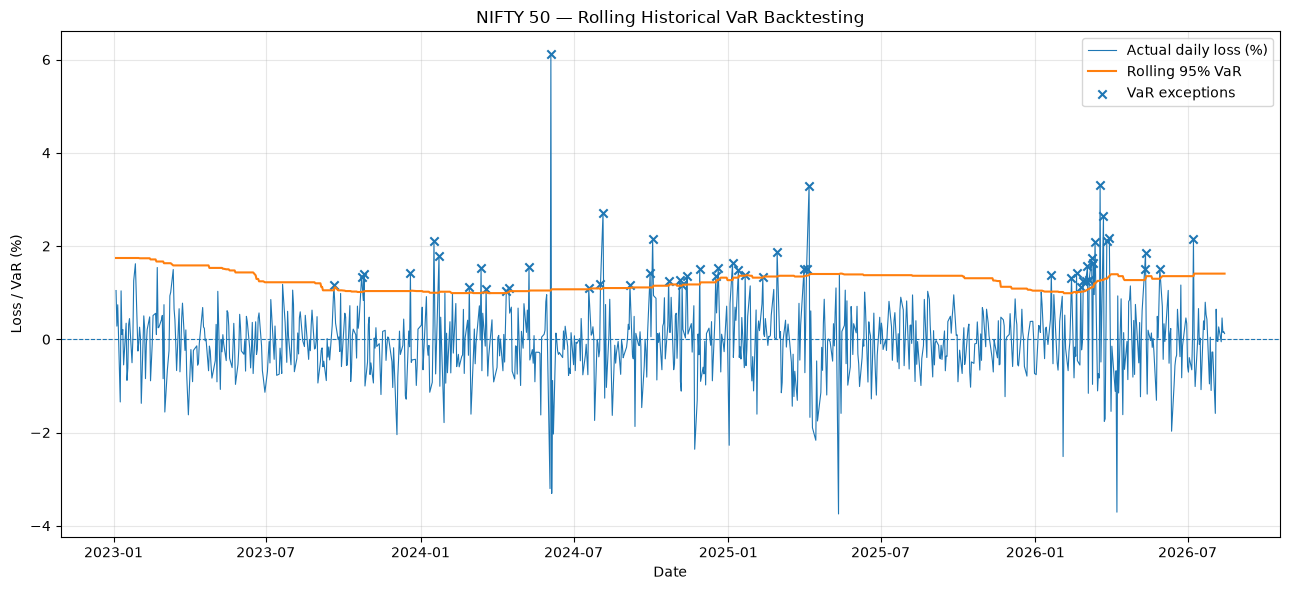

In [36]:
plt.figure(figsize=(13, 6))

plt.plot(
    backtest["Date"],
    backtest["Loss"],
    label="Actual daily loss (%)",
    linewidth=0.8
)

plt.plot(
    backtest["Date"],
    backtest["VaR_95"],
    label="Rolling 95% VaR",
    linewidth=1.5
)

exceptions = backtest[backtest["Exception_95"] == 1]

plt.scatter(
    exceptions["Date"],
    exceptions["Loss"],
    marker="x",
    label="VaR exceptions"
)

plt.axhline(0, linestyle="--", linewidth=0.8)

plt.title("NIFTY 50 — Rolling Historical VaR Backtesting")
plt.xlabel("Date")
plt.ylabel("Loss / VaR (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
vix_threshold = train_data["India_VIX"].quantile(0.90)

data["Market_Regime"] = np.where(
    data["India_VIX"] >= vix_threshold,
    "High Volatility",
    "Normal Volatility"
)

test_regimes = data.loc[
    data["Date"] >= test_start_date
].copy()

regime_summary = test_regimes.groupby("Market_Regime").agg(
    Observations=("NIFTY_Return", "size"),
    Average_Return=("NIFTY_Return", "mean"),
    Return_Std=("NIFTY_Return", "std"),
    Worst_Return=("NIFTY_Return", "min"),
    Average_India_VIX=("India_VIX", "mean"),
    Average_USA_VIX=("USA_VIX", "mean")
)

display(regime_summary.round(4))
print("Training-period 90th percentile of India VIX:", round(vix_threshold, 4))

,Observations,Average_Return,Return_Std,Worst_Return,Average_India_VIX,Average_USA_VIX
Market_Regime,,,,,,
Normal Volatility,886,0.0327,0.8053,-6.1124,13.8522,17.3538


Training-period 90th percentile of India VIX: 32.564


In [38]:
# Check the regime classification
print("India VIX threshold:", vix_threshold)

print("\nRegime counts in the full dataset:")
print(data["Market_Regime"].value_counts(dropna=False))

print("\nIndia VIX values in the test period:")
print(
    data.loc[data["Date"] >= test_start_date, "India_VIX"]
    .describe()
)

print("\nNumber of test observations above threshold:")
print(
    (
        data.loc[data["Date"] >= test_start_date, "India_VIX"]
        >= vix_threshold
    ).sum()
)

India VIX threshold: 32.564000000000014

Regime counts in the full dataset:
Market_Regime
Normal Volatility    4074
High Volatility       355
Name: count, dtype: int64

India VIX values in the test period:
count    886.000000
mean      13.852198
std        2.930664
min        9.150000
25%       11.788125
50%       13.303750
75%       15.024375
max       27.887500
Name: India_VIX, dtype: float64

Number of test observations above threshold:
0


In [39]:
# Define regimes using the training-period threshold
data["Market_Regime"] = np.where(
    data["India_VIX"] >= vix_threshold,
    "High Volatility",
    "Normal Volatility"
)

# Select test observations
test_regimes = data.loc[
    data["Date"] >= test_start_date
].copy()

# Summarise market behaviour by regime
regime_summary = test_regimes.groupby("Market_Regime").agg(
    Observations=("NIFTY_Return", "count"),
    Average_Return=("NIFTY_Return", "mean"),
    Return_Std=("NIFTY_Return", "std"),
    Worst_Return=("NIFTY_Return", "min"),
    Average_India_VIX=("India_VIX", "mean"),
    Average_USA_VIX=("USA_VIX", "mean")
)

display(regime_summary.round(4))

,Observations,Average_Return,Return_Std,Worst_Return,Average_India_VIX,Average_USA_VIX
Market_Regime,,,,,,
Normal Volatility,886,0.0327,0.8053,-6.1124,13.8522,17.3538


In [40]:
print("Threshold:", vix_threshold)

print("\nRegime counts:")
print(data["Market_Regime"].value_counts())

print("\nMaximum India VIX in test data:")
print(
    data.loc[data["Date"] >= test_start_date, "India_VIX"].max()
)

print("\nTest observations above threshold:")
print(
    (
        data.loc[data["Date"] >= test_start_date, "India_VIX"]
        >= vix_threshold
    ).sum()
)

Threshold: 32.564000000000014

Regime counts:
Market_Regime
Normal Volatility    4074
High Volatility       355
Name: count, dtype: int64

Maximum India VIX in test data:
27.8875

Test observations above threshold:
0


In [41]:
# Full-sample volatility regime comparison
full_regime_summary = data.groupby("Market_Regime").agg(
    Observations=("NIFTY_Return", "count"),
    Average_Return=("NIFTY_Return", "mean"),
    Return_Std=("NIFTY_Return", "std"),
    Worst_Return=("NIFTY_Return", "min"),
    Best_Return=("NIFTY_Return", "max"),
    Average_India_VIX=("India_VIX", "mean"),
    Average_USA_VIX=("USA_VIX", "mean")
)

display(full_regime_summary.round(4))

,Observations,Average_Return,Return_Std,Worst_Return,Best_Return,Average_India_VIX,Average_USA_VIX
Market_Regime,,,,,,,
High Volatility,355,-0.0608,2.9412,-13.9038,16.3343,43.8692,37.879
Normal Volatility,4074,0.0445,0.9779,-6.1124,5.1825,17.5812,18.185


In [42]:
# Compare return variability and average returns
high_returns = data.loc[
    data["Market_Regime"] == "High Volatility",
    "NIFTY_Return"
].dropna().to_numpy()

normal_returns = data.loc[
    data["Market_Regime"] == "Normal Volatility",
    "NIFTY_Return"
].dropna().to_numpy()

from scipy import stats
import numpy as np

# Welch's t-test: difference in mean returns
mean_test = stats.ttest_ind(
    high_returns,
    normal_returns,
    equal_var=False
)

# Levene's test: difference in variance
variance_test = stats.levene(
    high_returns,
    normal_returns,
    center="median"
)

print("MEAN RETURN COMPARISON")
print("High-volatility mean:", round(np.mean(high_returns), 4))
print("Normal-volatility mean:", round(np.mean(normal_returns), 4))
print("Welch t-statistic:", round(mean_test.statistic, 4))
print("Welch p-value:", round(mean_test.pvalue, 6))

print("\nRETURN VARIABILITY COMPARISON")
print("High-volatility standard deviation:", round(np.std(high_returns, ddof=1), 4))
print("Normal-volatility standard deviation:", round(np.std(normal_returns, ddof=1), 4))
print("Levene statistic:", round(variance_test.statistic, 4))
print("Levene p-value:", round(variance_test.pvalue, 6))

MEAN RETURN COMPARISON
High-volatility mean: -0.0608
Normal-volatility mean: 0.0445
Welch t-statistic: -0.6709
Welch p-value: 0.502737

RETURN VARIABILITY COMPARISON
High-volatility standard deviation: 2.9412
Normal-volatility standard deviation: 0.9779
Levene statistic: 878.3689
Levene p-value: 0.0


In [43]:
# CELL 1: Prepare variables for stress testing

import numpy as np
import pandas as pd

# Ensure chronological order
data = data.sort_values("Date").reset_index(drop=True)

# Create percentage changes if they are not already present
if "India_VIX_Change" not in data.columns:
    data["India_VIX_Change"] = data["India_VIX"].pct_change() * 100

if "USA_VIX_Change" not in data.columns:
    data["USA_VIX_Change"] = data["USA_VIX"].pct_change() * 100

# Use previous available US VIX change to avoid using
# same-day US market information in the NIFTY return model
data["Lagged_USA_VIX_Change"] = data["USA_VIX_Change"].shift(1)

# Recreate the chronological 80/20 split
data = data.replace([np.inf, -np.inf], np.nan)

split = int(len(data) * 0.80)

model_data = data.dropna(
    subset=[
        "NIFTY_Return",
        "India_VIX_Change",
        "Lagged_USA_VIX_Change"
    ]
).copy()

# Use the original chronological split date
split_date = data.iloc[split]["Date"]

train_model = model_data[model_data["Date"] < split_date].copy()
test_model = model_data[model_data["Date"] >= split_date].copy()

print("Training observations:", len(train_model))
print("Testing observations:", len(test_model))
print("Training period:", train_model["Date"].min(), "to", train_model["Date"].max())
print("Testing period:", test_model["Date"].min(), "to", test_model["Date"].max())

Training observations: 3542
Testing observations: 886
Training period: 2008-04-01 00:00:00 to 2023-01-03 00:00:00
Testing period: 2023-01-04 00:00:00 to 2026-08-14 00:00:00


In [44]:
# CELL 2: Fit regression using training data only

predictors = [
    "India_VIX_Change",
    "Lagged_USA_VIX_Change"
]

X_train = train_model[predictors].to_numpy(dtype=float)
y_train = train_model["NIFTY_Return"].to_numpy(dtype=float)

# Add the intercept column
X_train_design = np.column_stack([
    np.ones(len(X_train)),
    X_train
])

# Estimate coefficients using least squares
coefficients, residuals, rank, singular_values = np.linalg.lstsq(
    X_train_design,
    y_train,
    rcond=None
)

intercept = coefficients[0]
india_coef = coefficients[1]
usa_coef = coefficients[2]

print("Regression coefficients")
print("-----------------------")
print("Intercept:", round(intercept, 6))
print("India VIX change coefficient:", round(india_coef, 6))
print("Lagged US VIX change coefficient:", round(usa_coef, 6))

# In-sample training fit
train_predictions = X_train_design @ coefficients
train_rmse = np.sqrt(np.mean((y_train - train_predictions) ** 2))

print("\nTraining RMSE (% return):", round(train_rmse, 4))

Regression coefficients
-----------------------
Intercept: 0.057444
India VIX change coefficient: -0.084369
Lagged US VIX change coefficient: -0.019049

Training RMSE (% return): 1.212


In [45]:
# CELL 3: Define one-day VIX shock scenarios

portfolio_value = 1_000_000  # ₹10,00,000

scenarios = [
    ("Baseline: no VIX change", 0, 0),
    ("India VIX +25%", 25, 0),
    ("India VIX +50%", 50, 0),
    ("US VIX +25%", 0, 25),
    ("US VIX +50%", 0, 50),
    ("Both VIX +25%", 25, 25),
    ("Both VIX +50%", 50, 50)
]

stress_results = []

for scenario_name, india_shock, usa_shock in scenarios:

    predicted_return = (
        intercept
        + india_coef * india_shock
        + usa_coef * usa_shock
    )

    # Negative returns imply a portfolio loss
    estimated_loss = max(
        0,
        -predicted_return / 100 * portfolio_value
    )

    estimated_pnl = predicted_return / 100 * portfolio_value

    stress_results.append({
        "Scenario": scenario_name,
        "India_VIX_Shock_Percent": india_shock,
        "US_VIX_Shock_Percent": usa_shock,
        "Predicted_NIFTY_Return_Percent": predicted_return,
        "Estimated_Portfolio_PnL_INR": estimated_pnl,
        "Estimated_Portfolio_Loss_INR": estimated_loss
    })

stress_results_df = pd.DataFrame(stress_results)

display(stress_results_df.round(2))

stress_results_df.to_csv(
    "stress_testing_results_corrected.csv",
    index=False
)

print("Saved: stress_testing_results_corrected.csv")

,Scenario,India_VIX_Shock_Percent,US_VIX_Shock_Percent,Predicted_NIFTY_Return_Percent,Estimated_Portfolio_PnL_INR,Estimated_Portfolio_Loss_INR
0,Baseline: no VIX change,0,0,0.06,574.44,0.00
1,India VIX +25%,25,0,-2.05,-20517.79,20517.79
2,India VIX +50%,50,0,-4.16,-41610.03,41610.03
3,US VIX +25%,0,25,-0.42,-4187.73,4187.73
4,US VIX +50%,0,50,-0.89,-8949.91,8949.91
5,Both VIX +25%,25,25,-2.53,-25279.97,25279.97
6,Both VIX +50%,50,50,-5.11,-51134.38,51134.38


Saved: stress_testing_results_corrected.csv


In [46]:
# CELL 4: Evaluate regression on the test period

X_test = test_model[predictors].to_numpy(dtype=float)
y_test = test_model["NIFTY_Return"].to_numpy(dtype=float)

X_test_design = np.column_stack([
    np.ones(len(X_test)),
    X_test
])

test_predictions = X_test_design @ coefficients

# Evaluation metrics
test_rmse = np.sqrt(np.mean((y_test - test_predictions) ** 2))
test_mae = np.mean(np.abs(y_test - test_predictions))

ss_res = np.sum((y_test - test_predictions) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

test_r2 = 1 - ss_res / ss_tot

# Baseline prediction: training-period average return
baseline_prediction = np.mean(y_train)

baseline_rmse = np.sqrt(
    np.mean((y_test - baseline_prediction) ** 2)
)

baseline_mae = np.mean(
    np.abs(y_test - baseline_prediction)
)

print("OUT-OF-SAMPLE MODEL EVALUATION")
print("--------------------------------")
print("Test observations:", len(y_test))
print("Model RMSE:", round(test_rmse, 4), "%")
print("Model MAE:", round(test_mae, 4), "%")
print("Test R-squared:", round(test_r2, 4))

print("\nBASELINE COMPARISON")
print("-------------------")
print("Baseline RMSE:", round(baseline_rmse, 4), "%")
print("Baseline MAE:", round(baseline_mae, 4), "%")

OUT-OF-SAMPLE MODEL EVALUATION
--------------------------------
Test observations: 886
Model RMSE: 0.6558 %
Model MAE: 0.5003 %
Test R-squared: 0.3359

BASELINE COMPARISON
-------------------
Baseline RMSE: 0.8048 %
Baseline MAE: 0.5818 %


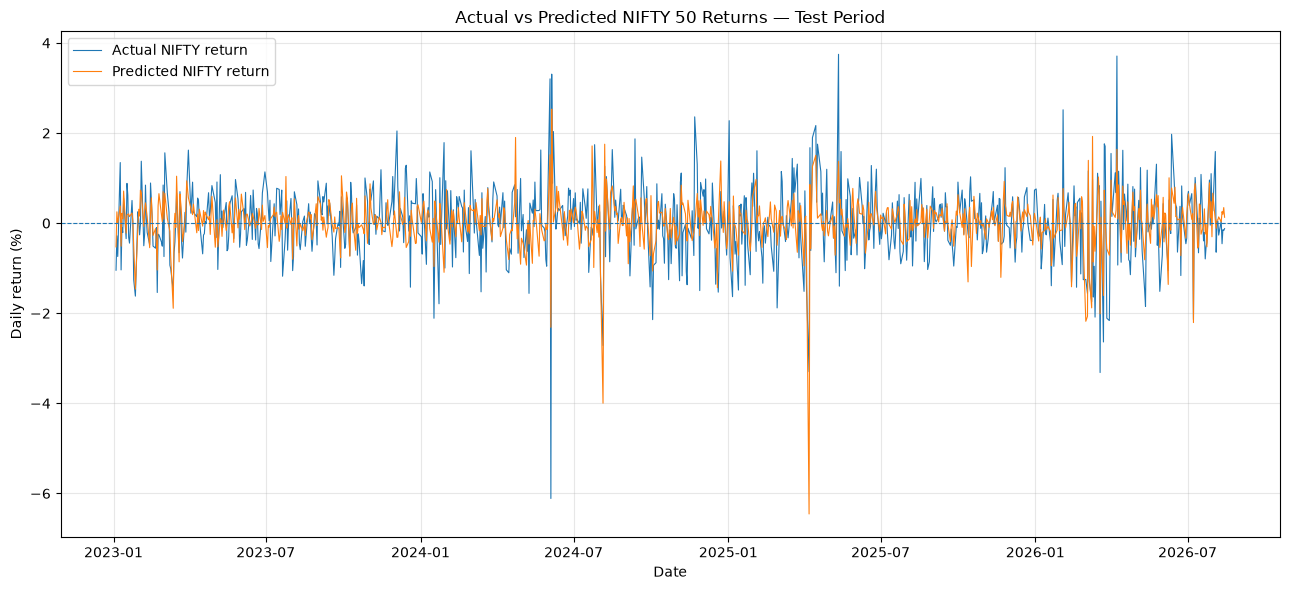

In [47]:
# CELL 5: Actual vs predicted returns

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 6))

plt.plot(
    test_model["Date"],
    y_test,
    label="Actual NIFTY return",
    linewidth=0.8
)

plt.plot(
    test_model["Date"],
    test_predictions,
    label="Predicted NIFTY return",
    linewidth=0.8
)

plt.axhline(0, linestyle="--", linewidth=0.8)

plt.title("Actual vs Predicted NIFTY 50 Returns — Test Period")
plt.xlabel("Date")
plt.ylabel("Daily return (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()